# EN3330 Assignment 03 — Plots
Lagrangian duality example: $\min x^2$ subject to $x \ge 1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11, "figure.dpi": 120})

## Q1(a): $L(\mu,x)=x^2+\mu(1-x)$ vs $x$, for $\mu=0,1,2,3$
Minimizer of each curve is $x(\mu)=\mu/2$ (marked with a dot).

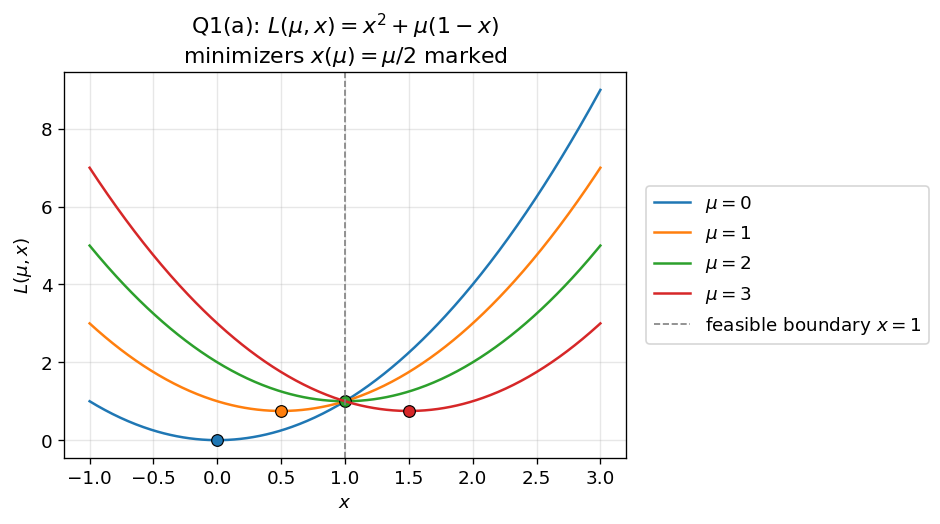

In [2]:
x = np.linspace(-1, 3, 400)
mus = [0, 1, 2, 3]
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

fig, ax = plt.subplots(figsize=(8, 4.5))
for mu, c in zip(mus, colors):
    L = x**2 + mu * (1 - x)
    ax.plot(x, L, color=c, label=f"$\\mu={mu}$")
    xm = mu / 2
    Lm = xm**2 + mu * (1 - xm)
    ax.plot(xm, Lm, "o", color=c, ms=7, mec="k", mew=0.7)

ax.axvline(1, color="gray", ls="--", lw=1, label="feasible boundary $x=1$")
ax.set_xlabel("$x$")
ax.set_ylabel("$L(\\mu, x)$")
ax.set_title("Q1(a): $L(\\mu,x)=x^2+\\mu(1-x)$\nminimizers $x(\\mu)=\\mu/2$ marked")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("q1a_L_vs_x.png")
plt.show()

## Q1(b): dual function $d(\mu) = \min_x L(\mu,x) = \mu - \mu^2/4$
$\mu^* = \arg\max_{\mu\ge0} d(\mu) = 2$, $d^* = d(2) = 1$.

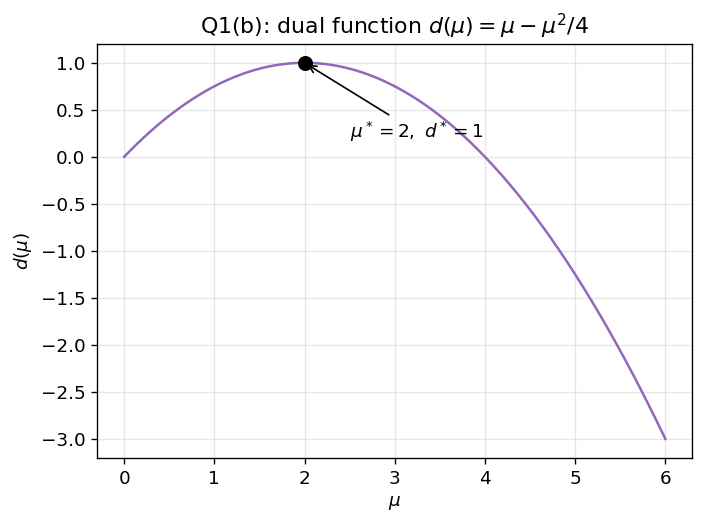

In [3]:
mu_range = np.linspace(0, 6, 400)
d = mu_range - mu_range**2 / 4

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(mu_range, d, color="tab:purple")

mu_star, d_star = 2, 1
ax.plot(mu_star, d_star, "o", color="k", ms=8)
ax.annotate(
    f"$\\mu^*={mu_star},\\ d^*={d_star}$",
    xy=(mu_star, d_star),
    xytext=(mu_star + 0.5, d_star - 0.8),
    arrowprops=dict(arrowstyle="->"),
)

ax.set_xlabel("$\\mu$")
ax.set_ylabel("$d(\\mu)$")
ax.set_title("Q1(b): dual function $d(\\mu)=\\mu-\\mu^2/4$")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("q1b_dual.png")
plt.show()

## Q1(c): primal function $g(x) = \max_{\mu\ge0} L(\mu,x)$
$g(x)=x^2$ for feasible $x\ge1$, and $g(x)=+\infty$ for infeasible $x<1$
(shown here with upward arrows instead of actually plotting infinity).

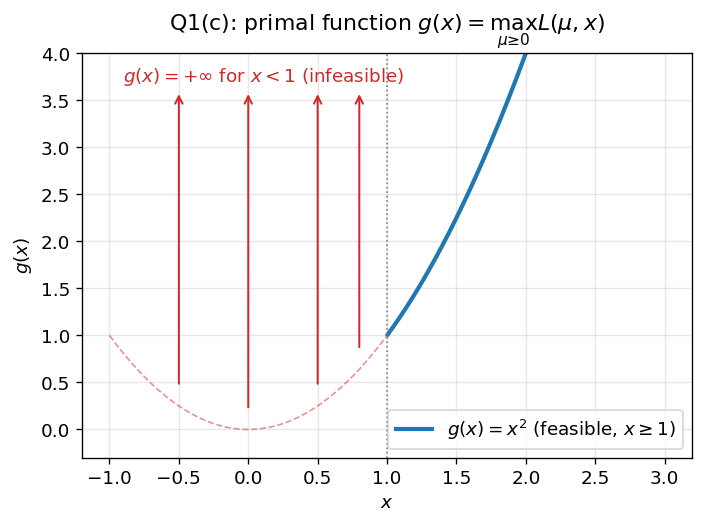

In [7]:
x2 = np.linspace(-1, 3, 400)
g = np.where(x2 >= 1, x2**2, np.nan)  # finite (feasible) part only

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(x2, g, color="tab:blue", lw=2.5, label="$g(x)=x^2$ (feasible, $x\\geq1$)")

xs_inf = np.linspace(-1, 0.999, 100)
ax.plot(xs_inf, xs_inf**2, color="tab:red", lw=1, ls="--", alpha=0.5)
for xv in [-0.5, 0, 0.5, 0.8]:
    ax.annotate(
        "", xy=(xv, 3.6), xytext=(xv, xv**2 + 0.2),
        arrowprops=dict(arrowstyle="->", color="tab:red", lw=1.2),
    )
ax.text(-0.9, 3.7, "$g(x)=+\\infty$ for $x<1$ (infeasible)", color="tab:red")
ax.axvline(1, color="gray", ls=":", lw=1)

ax.set_xlabel("$x$")
ax.set_ylabel("$g(x)$")
ax.set_ylim(-0.3, 4)
ax.set_title("Q1(c): primal function $g(x)=\\max_{\\mu\\geq0}L(\\mu,x)$", pad=14)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("q1c_primal.png")
plt.show()

## Q2(a)(iv): saddle point at $(\mu^*, x^*) = (2, 1)$
Left: $L(\mu, x^*)=1$ (constant in $\mu$). Right: $L(\mu^*, x)=(x-1)^2+1$.
Both touch the common value $L(\mu^*,x^*)=1$.

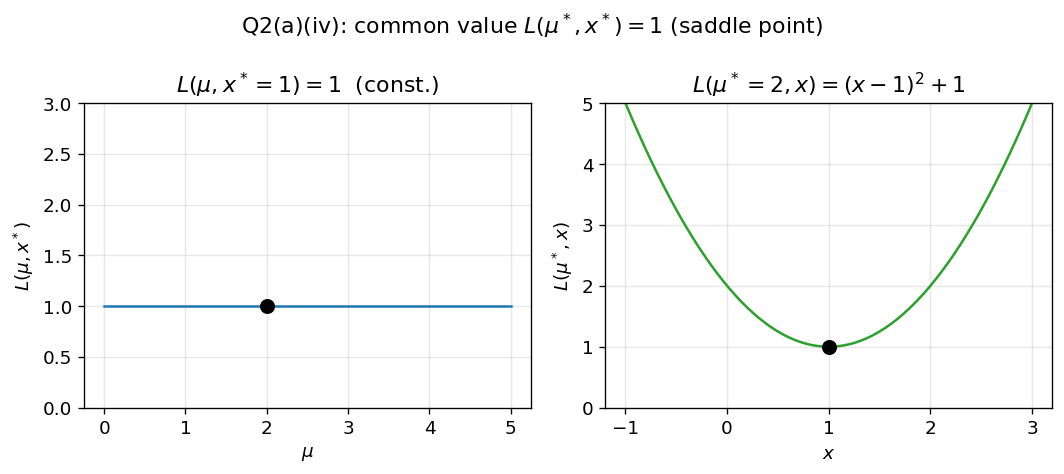

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

mu_r = np.linspace(0, 5, 200)
Lmu_xstar = np.ones_like(mu_r) * 1.0  # L(mu, x*=1) = 1 for all mu
axes[0].plot(mu_r, Lmu_xstar, color="tab:blue")
axes[0].plot(2, 1, "o", color="k", ms=8)
axes[0].set_xlabel("$\\mu$")
axes[0].set_ylabel("$L(\\mu, x^*)$")
axes[0].set_title("$L(\\mu, x^*=1) = 1$  (const.)")
axes[0].set_ylim(0, 3)
axes[0].grid(alpha=0.3)

x_r = np.linspace(-1, 3, 200)
Lmustar_x = (x_r - 1) ** 2 + 1
axes[1].plot(x_r, Lmustar_x, color="tab:green")
axes[1].plot(1, 1, "o", color="k", ms=8)
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("$L(\\mu^*, x)$")
axes[1].set_title("$L(\\mu^*=2, x) = (x-1)^2+1$")
axes[1].set_ylim(0, 5)
axes[1].grid(alpha=0.3)

fig.suptitle("Q2(a)(iv): common value $L(\\mu^*,x^*)=1$ (saddle point)")
fig.tight_layout()
fig.savefig("q2a_saddle.png")
plt.show()

## Q3(b): $L(\mu,x)$ vs $\mu$ for $x=0,1,2$ — lower envelope approximates $d(\mu)$
Each is affine (a straight line) in $\mu$; the pointwise minimum of a family of affine
functions is always concave, which is why $d(\mu)$ is concave for *any* $f$, convex or not.

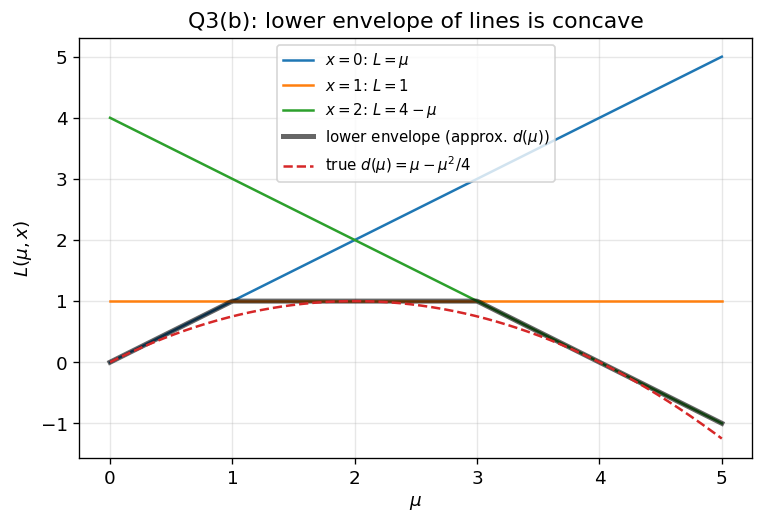

In [6]:
mu_r2 = np.linspace(0, 5, 400)
L_x0 = mu_r2                     # x=0: L = mu
L_x1 = np.ones_like(mu_r2) * 1    # x=1: L = 1
L_x2 = 4 - mu_r2                  # x=2: L = 4-mu

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(mu_r2, L_x0, label="$x=0$: $L=\\mu$", color="tab:blue")
ax.plot(mu_r2, L_x1, label="$x=1$: $L=1$", color="tab:orange")
ax.plot(mu_r2, L_x2, label="$x=2$: $L=4-\\mu$", color="tab:green")

env = np.minimum(np.minimum(L_x0, L_x1), L_x2)
ax.plot(mu_r2, env, color="k", lw=3, alpha=0.6, label="lower envelope (approx. $d(\\mu)$)")
ax.plot(mu_r2, mu_r2 - mu_r2**2 / 4, color="tab:red", lw=1.5, ls="--", label="true $d(\\mu)=\\mu-\\mu^2/4$")

ax.set_xlabel("$\\mu$")
ax.set_ylabel("$L(\\mu,x)$")
ax.set_title("Q3(b): lower envelope of lines is concave")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("q3b_envelope.png")
plt.show()